In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


##PART -A

In [ ]:
STUDENT_ID = "PES2UG24CS655"

# AUTOMATIC ASSIGNMENT BASED ON SRN - DO NOT MODIFY

In [ ]:
def get_student_assignment(student_id):
    """
    Generate unique polynomial TYPE and architecture based on student ID
    Uses last 3 digits of student ID for assignment
    """

    last_three = int(student_id[-3:])

    poly_type = last_three % 5

    np.random.seed(last_three)

    if poly_type == 0:
        degree = 2
        a = 0
        b = np.random.uniform(0.8, 1.5)
        c = np.random.uniform(3.0, 8.0)
        d = np.random.uniform(5.0, 15.0)
        poly_desc = f"QUADRATIC: y = {b:.2f}x² + {c:.2f}x + {d:.2f}"

    elif poly_type == 1:
        degree = 3
        a = np.random.uniform(1.8, 2.5)
        b = np.random.uniform(-1.2, 0.2)
        c = np.random.uniform(3.0, 6.0)
        d = np.random.uniform(8.0, 12.0)
        poly_desc = f"CUBIC: y = {a:.2f}x³ + {b:.2f}x² + {c:.2f}x + {d:.2f}"

    elif poly_type == 2:
        degree = 4
        a = np.random.uniform(0.008, 0.02)
        b = np.random.uniform(1.5, 2.2)
        c = np.random.uniform(-1.0, 0.5)
        d = np.random.uniform(2.0, 5.0)
        e = np.random.uniform(8.0, 12.0)
        poly_desc = f"QUARTIC: y = {a:.4f}x⁴ + {b:.2f}x³ + {c:.2f}x² + {d:.2f}x + {e:.2f}"
        coefficients = (a, b, c, d, e)

    elif poly_type == 3:
        degree = "sine"
        a = np.random.uniform(1.5, 2.8)
        b = np.random.uniform(-0.8, 0.8)
        c = np.random.uniform(3.0, 6.0)
        d = np.random.uniform(8.0, 12.0)
        freq = np.random.uniform(0.02, 0.05)
        amp = np.random.uniform(5.0, 15.0)
        poly_desc = f"CUBIC + SINE: y = {a:.2f}x³ + {b:.2f}x² + {c:.2f}x + {d:.2f} + {amp:.1f}*sin({freq:.3f}x)"
        coefficients = (a, b, c, d, freq, amp)

    else:
        degree = "inverse"
        a = np.random.uniform(1.8, 2.5)
        b = np.random.uniform(-1.0, 0.5)
        c = np.random.uniform(3.0, 6.0)
        d = np.random.uniform(8.0, 12.0)
        inv_coeff = np.random.uniform(50, 200)
        poly_desc = f"CUBIC + INVERSE: y = {a:.2f}x³ + {b:.2f}x² + {c:.2f}x + {d:.2f} + {inv_coeff:.1f}/x"
        coefficients = (a, b, c, d, inv_coeff)


    if poly_type in [0, 1]:
        coefficients = (a, b, c, d)


    noise_std = np.random.uniform(1.5, 2.5)


    arch_type = last_three % 4
    architectures = {
        0: {"hidden1": 64, "hidden2": 64, "lr": 0.001, "batch_desc": "Balanced Architecture"},
        1: {"hidden1": 32, "hidden2": 72, "lr": 0.005, "batch_desc": "Narrow-to-Wide Architecture"},
        2: {"hidden1": 72, "hidden2": 32, "lr": 0.001, "batch_desc": "Wide-to-Narrow Architecture"},
        3: {"hidden1": 96, "hidden2": 96, "lr": 0.003, "batch_desc": "Large Balanced Architecture"}
    }

    return {
        "polynomial_type": poly_type,
        "degree": degree,
        "coefficients": coefficients,
        "polynomial_desc": poly_desc,
        "noise_std": noise_std,
        "architecture": architectures[arch_type],
        "student_seed": last_three
    }

# Get your assignment
assignment = get_student_assignment(STUDENT_ID)
poly_type = assignment["polynomial_type"]
degree = assignment["degree"]
coefficients = assignment["coefficients"]
noise_std = assignment["noise_std"]
hidden1 = assignment["architecture"]["hidden1"]
hidden2 = assignment["architecture"]["hidden2"]
learning_rate = assignment["architecture"]["lr"]

print("="*70)
print(f"ASSIGNMENT FOR STUDENT ID: {STUDENT_ID}")
print("="*70)
print(f"Polynomial Type: {assignment['polynomial_desc']}")
print(f"Noise Level: ε ~ N(0, {noise_std:.2f})")
print(f"Architecture: Input(1) → Hidden({hidden1}) → Hidden({hidden2}) → Output(1)")
print(f"Learning Rate: {learning_rate}")
print(f"Architecture Type: {assignment['architecture']['batch_desc']}")
print("="*70)


ASSIGNMENT FOR STUDENT ID: PES2UG24CS655
Polynomial Type: QUADRATIC: y = 0.94x² + 6.44x + 14.34
Noise Level: ε ~ N(0, 1.64)
Architecture: Input(1) → Hidden(96) → Hidden(96) → Output(1)
Learning Rate: 0.003
Architecture Type: Large Balanced Architecture


# DATASET GENERATION - DO NOT MODIFY

In [ ]:
np.random.seed(assignment["student_seed"])

n_samples = 100000
x = np.random.uniform(-100, 100, n_samples)


if poly_type == 0:
    _, b, c, d = coefficients
    y = b * x**2 + c * x + d + np.random.normal(0, noise_std, n_samples)

elif poly_type == 1:
    a, b, c, d = coefficients
    y = a * x**3 + b * x**2 + c * x + d + np.random.normal(0, noise_std, n_samples)

elif poly_type == 2:
    a, b, c, d, e = coefficients
    y = a * x**4 + b * x**3 + c * x**2 + d * x + e + np.random.normal(0, noise_std, n_samples)

elif poly_type == 3:
    a, b, c, d, freq, amp = coefficients
    y = a * x**3 + b * x**2 + c * x + d + amp * np.sin(freq * x) + np.random.normal(0, noise_std, n_samples)

else:
    a, b, c, d, inv_coeff = coefficients

    y = a * x**3 + b * x**2 + c * x + d + inv_coeff / (x + np.sign(x) * 0.1) + np.random.normal(0, noise_std, n_samples)


df = pd.DataFrame({'x': x, 'y': y})
df.to_csv('student_polynomial_dataset.csv', index=False)
print(f"Dataset with {n_samples:,} samples generated and saved!")

X = df['x'].values.reshape(-1, 1)
Y = df['y'].values.reshape(-1, 1)

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

scaler_X = StandardScaler()
scaler_Y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)
Y_train_scaled = scaler_Y.fit_transform(Y_train)
Y_test_scaled = scaler_Y.transform(Y_test)

print(f"Training samples: {len(X_train_scaled):,}")
print(f"Test samples: {len(X_test_scaled):,}")

Dataset with 100,000 samples generated and saved!
Training samples: 80,000
Test samples: 20,000


# ACTIVATION FUNCTIONS- TODO: IMPLEMENT

In [ ]:
def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

# LOSS FUNCTION- TODO: IMPLEMENT

In [ ]:
def mse_loss(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

# WEIGHT INITIALIZATION - TODO: IMPLEMENT XAVIER INITIALIZATION
## **Xavier (Glorot) Initialization**

When training neural networks, how we initialize weights matters.  
- If weights are **too small** → activations and gradients vanish.  
- If weights are **too large** → activations and gradients explode.  

#**Xavier initialization** (Glorot & Bengio, 2010) balances this by keeping the variance of activations roughly the same across all layers.

---

### Formula

Let:  
- **fan_in** = number of input units to a layer  
- **fan_out** = number of output units from a layer  

The variance of weights is:

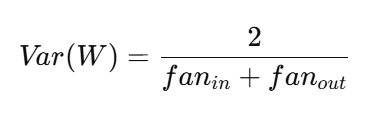


##Two common forms:  

#**Normal distribution:**  
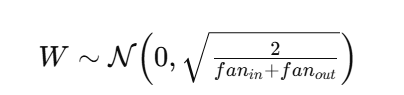

#**Uniform distribution:**  
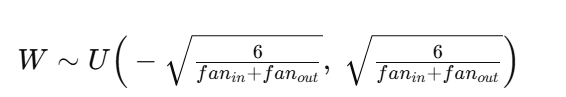

Biases are initialized to **0**.

---

### In This Assignment
- **W1 (input → hidden1):** `fan_in = input_dim`, `fan_out = hidden1`  
- **W2 (hidden1 → hidden2):** `fan_in = hidden1`, `fan_out = hidden2`  
- **W3 (hidden2 → output):** `fan_in = hidden2`, `fan_out = output_dim`  

Your task: compute the correct `xavier_std` for each layer, sample weights from a normal distribution with that std, and set biases = 0.



In [ ]:
def xavier_initialization(input_dim, hidden1, hidden2, output_dim):
    """
    Xavier weight initialization
    """

    np.random.seed(assignment["student_seed"])

    # Standard deviation for each layer
    std1 = np.sqrt(2 / (input_dim + hidden1))
    std2 = np.sqrt(2 / (hidden1 + hidden2))
    std3 = np.sqrt(2 / (hidden2 + output_dim))

    # Input → Hidden 1
    W1 = np.random.normal(0, std1, (input_dim, hidden1))
    b1 = np.zeros((1, hidden1))

    # Hidden 1 → Hidden 2
    W2 = np.random.normal(0, std2, (hidden1, hidden2))
    b2 = np.zeros((1, hidden2))

    # Hidden 2 → Output
    W3 = np.random.normal(0, std3, (hidden2, output_dim))
    b3 = np.zeros((1, output_dim))

    return W1, b1, W2, b2, W3, b3

# FORWARD PROPAGATION - TODO: IMPLEMENT

In [ ]:
def forward_pass(X, W1, b1, W2, b2, W3, b3):

    # First hidden layer
    z1 = X @ W1 + b1
    a1 = relu(z1)

    # Second hidden layer
    z2 = a1 @ W2 + b2
    a2 = relu(z2)

    # Output layer
    z3 = a2 @ W3 + b3

    return z1, a1, z2, a2, z3

# BACKWARD PROPAGATION - TODO:IMPLEMENT

In [ ]:
def backward_pass(X, Y_true, z1, a1, z2, a2, Y_pred, W2, W3):

    m = len(X)

    # Derivative of MSE
    dY_pred = (2 / m) * (Y_pred - Y_true)

    # Output layer
    dW3 = a2.T @ dY_pred
    db3 = np.sum(dY_pred, axis=0, keepdims=True)

    # Second hidden layer
    da2 = dY_pred @ W3.T
    dz2 = da2 * relu_derivative(z2)

    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # First hidden layer
    da1 = dz2 @ W2.T
    dz1 = da1 * relu_derivative(z1)

    dW1 = X.T @ dz1
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2, dW3, db3

# TRAINING FUNCTION - TODO:  COMPLETE IMPLEMENTATION

In [ ]:
def train_neural_network(X_train, Y_train, X_test, Y_test, epochs=200, patience=10):
    """
    TODO: COMPLETE THE TRAINING LOOP

    Implement training with early stopping and track losses

    Args:
        X_train, Y_train: Training data
        X_test, Y_test: Test data for validation
        epochs: Maximum number of training epochs
        patience: Early stopping patience

    Returns:
        best_weights: Best model weights
        train_losses: Training loss history
        test_losses: Test loss history
    """


    W1, b1, W2, b2, W3, b3 = xavier_initialization(1, hidden1, hidden2, 1)

    best_test_loss = float('inf')
    best_weights = None
    patience_counter = 0

    train_losses = []
    test_losses = []

    print("Starting training...")
    print(f"Architecture: 1 → {hidden1} → {hidden2} → 1")
    print(f"Learning Rate: {learning_rate}")
    print(f"Max Epochs: {epochs}, Early Stopping Patience: {patience}")
    print("-" * 50)

    for epoch in range(epochs):


        z1, a1, z2, a2, Y_pred_train = forward_pass(X_train, W1, b1, W2, b2, W3, b3)


        train_loss = mse_loss(Y_train, Y_pred_train)


        dW1, db1, dW2, db2, dW3, db3 = backward_pass(X_train, Y_train, z1, a1, z2, a2, Y_pred_train, W2, W3)


        W1 = W1 - learning_rate * dW1
        b1 = b1 - learning_rate * db1

        W2 = W2 - learning_rate * dW2
        b2 = b2 - learning_rate * db2

        W3 = W3 - learning_rate * dW3
        b3 = b3 - learning_rate * db3


        _, _, _, _, Y_pred_test = forward_pass(X_test, W1, b1, W2, b2, W3, b3)
        test_loss = mse_loss(Y_test, Y_pred_test)


        train_losses.append(train_loss)
        test_losses.append(test_loss)

        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch+1:3d}: Train Loss = {train_loss:.6f}, Test Loss = {test_loss:.6f}")

        if test_loss < best_test_loss:
            best_test_loss = test_loss
            best_weights = (W1.copy(), b1.copy(), W2.copy(), b2.copy(), W3.copy(), b3.copy())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print(f"Early stopping triggered at epoch {epoch+1}")
            print(f"Best test loss: {best_test_loss:.6f}")
            break

    return best_weights, train_losses, test_losses


# EXECUTE TRAINING

In [ ]:
print("Training Neural Network with your specific configuration...")
weights, train_losses, test_losses = train_neural_network(
    X_train_scaled, Y_train_scaled, X_test_scaled, Y_test_scaled,
    epochs=500, patience=10
)

Training Neural Network with your specific configuration...
Starting training...
Architecture: 1 → 96 → 96 → 1
Learning Rate: 0.003
Max Epochs: 500, Early Stopping Patience: 10
--------------------------------------------------
Epoch  20: Train Loss = 0.941212, Test Loss = 0.944109
Epoch  40: Train Loss = 0.909062, Test Loss = 0.911213
Epoch  60: Train Loss = 0.878344, Test Loss = 0.879919
Epoch  80: Train Loss = 0.848706, Test Loss = 0.849798
Epoch 100: Train Loss = 0.819669, Test Loss = 0.820363
Epoch 120: Train Loss = 0.790897, Test Loss = 0.791259
Epoch 140: Train Loss = 0.762039, Test Loss = 0.762146
Epoch 160: Train Loss = 0.733099, Test Loss = 0.733017
Epoch 180: Train Loss = 0.704136, Test Loss = 0.703900
Epoch 200: Train Loss = 0.674627, Test Loss = 0.674253
Epoch 220: Train Loss = 0.644439, Test Loss = 0.643977
Epoch 240: Train Loss = 0.614013, Test Loss = 0.613529
Epoch 260: Train Loss = 0.584704, Test Loss = 0.584243
Epoch 280: Train Loss = 0.556342, Test Loss = 0.555900
Ep

# RESULTS VISUALIZATION

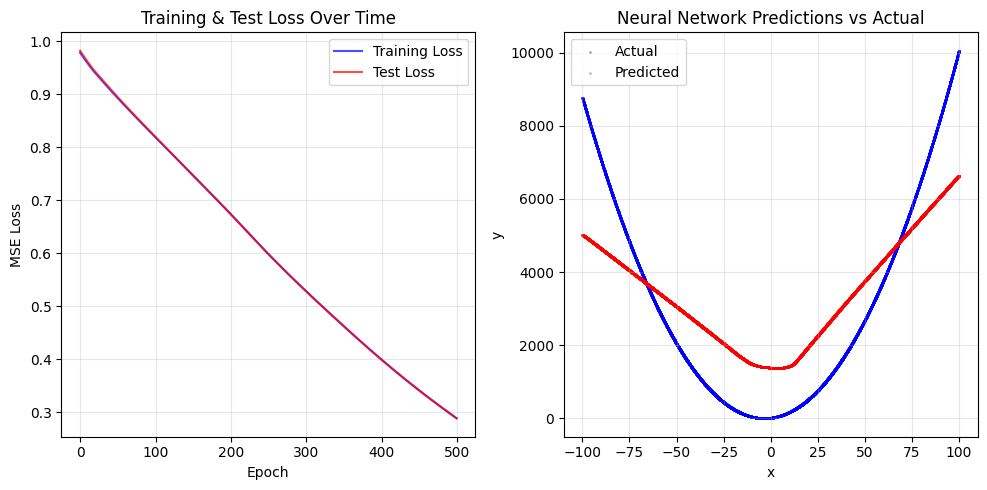

In [ ]:
# Plot training progress
plt.figure(figsize=(15, 5))

# Loss curves
plt.subplot(1, 3, 1)
plt.plot(train_losses, label='Training Loss', color='blue', alpha=0.7)
plt.plot(test_losses, label='Test Loss', color='red', alpha=0.7)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training & Test Loss Over Time')
plt.legend()
plt.grid(True, alpha=0.3)

# Get final predictions for visualization
W1, b1, W2, b2, W3, b3 = weights
_, _, _, _, Y_pred_scaled = forward_pass(X_test_scaled, W1, b1, W2, b2, W3, b3)

# Inverse transform to original scale
Y_test_orig = scaler_Y.inverse_transform(Y_test_scaled)
Y_pred_orig = scaler_Y.inverse_transform(Y_pred_scaled)
X_test_orig = scaler_X.inverse_transform(X_test_scaled)

# Predictions vs Actual
plt.subplot(1, 3, 2)
plt.scatter(X_test_orig, Y_test_orig, s=1, alpha=0.3, label='Actual', color='blue')
plt.scatter(X_test_orig, Y_pred_orig, s=1, alpha=0.3, label='Predicted', color='red')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Neural Network Predictions vs Actual')
plt.legend()
plt.grid(True, alpha=0.3)

# Residual plot
# plt.subplot(1, 3, 3)
# residuals = Y_test_orig.flatten() - Y_pred_orig.flatten()
# plt.scatter(X_test_orig, residuals, s=1, alpha=0.3, color='green')
# plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)
# plt.xlabel('x')
# plt.ylabel('Residuals (Actual - Predicted)')
# plt.title('Residual Analysis')
# plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

SPECIFIC PREDICTION TEST

In [ ]:

x_test_value = 90.2
x_new = np.array([[x_test_value]])
x_new_scaled = scaler_X.transform(x_new)

_, _, _, _, y_pred_scaled = forward_pass(x_new_scaled, W1, b1, W2, b2, W3, b3)
y_pred = scaler_Y.inverse_transform(y_pred_scaled)

if poly_type == 0:
    _, b, c, d = coefficients
    y_true = b * x_test_value**2 + c * x_test_value + d

elif poly_type == 1:
    a, b, c, d = coefficients
    y_true = a * x_test_value**3 + b * x_test_value**2 + c * x_test_value + d

elif poly_type == 2:
    a, b, c, d, e = coefficients
    y_true = a * x_test_value**4 + b * x_test_value**3 + c * x_test_value**2 + d * x_test_value + e

elif poly_type == 3:
    a, b, c, d, freq, amp = coefficients
    y_true = a * x_test_value**3 + b * x_test_value**2 + c * x_test_value + d + amp * np.sin(freq * x_test_value)

else:
    a, b, c, d, inv_coeff = coefficients
    y_true = a * x_test_value**3 + b * x_test_value**2 + c * x_test_value + d + inv_coeff / (x_test_value + np.sign(x_test_value) * 0.1)

print("\n" + "="*60)
print("PREDICTION RESULTS FOR x = 90.2")
print("="*60)
print(f"Neural Network Prediction: {y_pred[0][0]:,.2f}")
print(f"Ground Truth (formula):    {y_true:,.2f}")
print(f"Absolute Error:            {abs(y_pred[0][0] - y_true):,.2f}")
print(f"Relative Error:            {abs(y_pred[0][0] - y_true)/abs(y_true)*100:.3f}%")




PREDICTION RESULTS FOR x = 90.2
Neural Network Prediction: 6,081.88
Ground Truth (formula):    8,243.48
Absolute Error:            2,161.59
Relative Error:            26.222%


# PERFORMANCE METRICS

In [ ]:
# Calculate final performance metrics
final_train_loss = train_losses[-1] if train_losses else float('inf')
final_test_loss = test_losses[-1] if test_losses else float('inf')

# Calculate R² score
y_test_mean = np.mean(Y_test_orig)
ss_res = np.sum((Y_test_orig - Y_pred_orig) ** 2)
ss_tot = np.sum((Y_test_orig - y_test_mean) ** 2)
r2_score = 1 - (ss_res / ss_tot)

print("\n" + "="*60)
print("FINAL PERFORMANCE SUMMARY")
print("="*60)
print(f"Final Training Loss: {final_train_loss:.6f}")
print(f"Final Test Loss:     {final_test_loss:.6f}")
print(f"R² Score:           {r2_score:.4f}")
print(f"Total Epochs Run:   {len(train_losses)}")


FINAL PERFORMANCE SUMMARY
Final Training Loss: 0.288528
Final Test Loss:     0.288321
R² Score:           0.7135
Total Epochs Run:   500


  [Baseline] Epoch 100/500 | Train Loss: 0.81780 | Val Loss: 0.82319
  [Baseline] Epoch 200/500 | Train Loss: 0.67294 | Val Loss: 0.67729
  [Baseline] Epoch 300/500 | Train Loss: 0.52757 | Val Loss: 0.53080
  [Baseline] Epoch 400/500 | Train Loss: 0.39867 | Val Loss: 0.40120
  [Baseline] Epoch 500/500 | Train Loss: 0.28767 | Val Loss: 0.28967


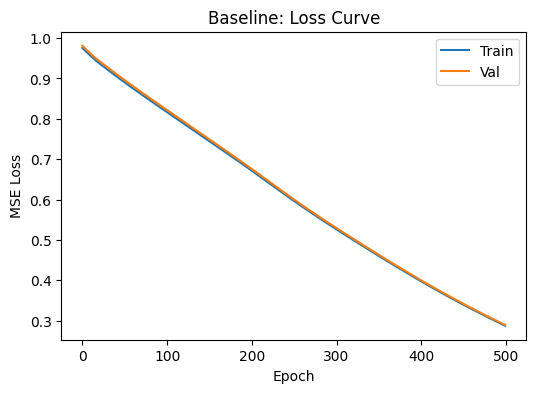

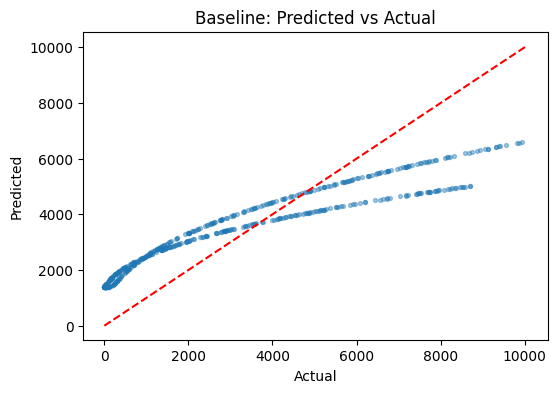

  [Exp1_HigherLR] Epoch 100/500 | Train Loss: 0.28906 | Val Loss: 0.29107
  [Exp1_HigherLR] Epoch 200/500 | Train Loss: 0.05046 | Val Loss: 0.05085
  [Exp1_HigherLR] Epoch 300/500 | Train Loss: 0.02689 | Val Loss: 0.02681
  [Exp1_HigherLR] Epoch 400/500 | Train Loss: 0.01829 | Val Loss: 0.01812
  [Exp1_HigherLR] Epoch 500/500 | Train Loss: 0.01294 | Val Loss: 0.01277


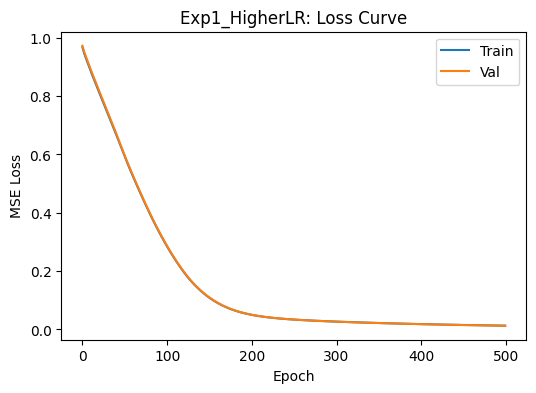

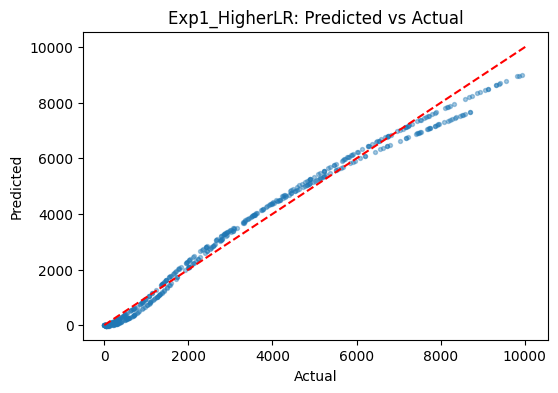

  [Exp2_LargerBatch] Epoch 100/500 | Train Loss: 0.01940 | Val Loss: 0.01925
  [Exp2_LargerBatch] Epoch 200/500 | Train Loss: 0.00645 | Val Loss: 0.00633
  [Exp2_LargerBatch] Epoch 300/500 | Train Loss: 0.00302 | Val Loss: 0.00295
  [Exp2_LargerBatch] Epoch 400/500 | Train Loss: 0.00167 | Val Loss: 0.00162
  [Exp2_LargerBatch] Epoch 500/500 | Train Loss: 0.00105 | Val Loss: 0.00101


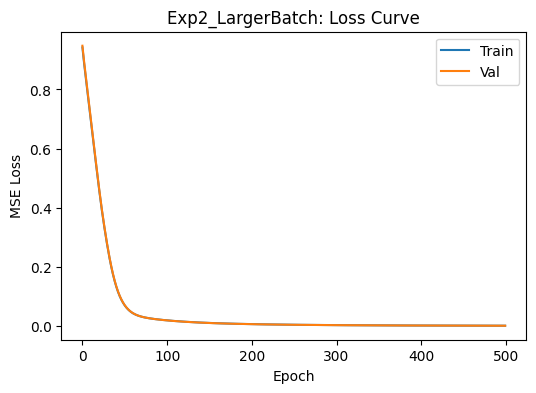

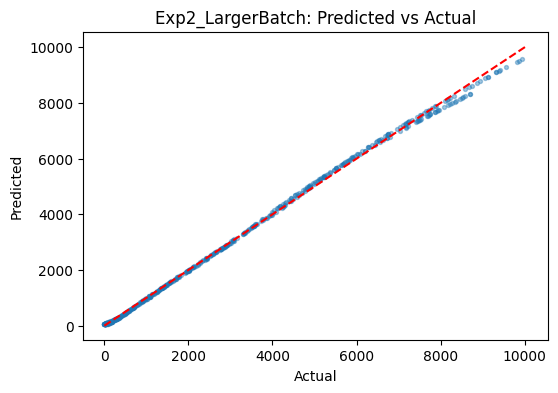

  [Exp3_MoreEpochs] Epoch 100/700 | Train Loss: 0.81780 | Val Loss: 0.82319
  [Exp3_MoreEpochs] Epoch 200/700 | Train Loss: 0.67294 | Val Loss: 0.67729
  [Exp3_MoreEpochs] Epoch 300/700 | Train Loss: 0.52757 | Val Loss: 0.53080
  [Exp3_MoreEpochs] Epoch 400/700 | Train Loss: 0.39867 | Val Loss: 0.40120
  [Exp3_MoreEpochs] Epoch 500/700 | Train Loss: 0.28767 | Val Loss: 0.28967
  [Exp3_MoreEpochs] Epoch 600/700 | Train Loss: 0.19770 | Val Loss: 0.19927
  [Exp3_MoreEpochs] Epoch 700/700 | Train Loss: 0.13351 | Val Loss: 0.13472


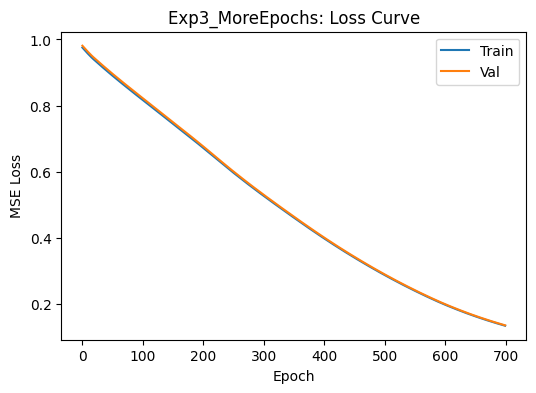

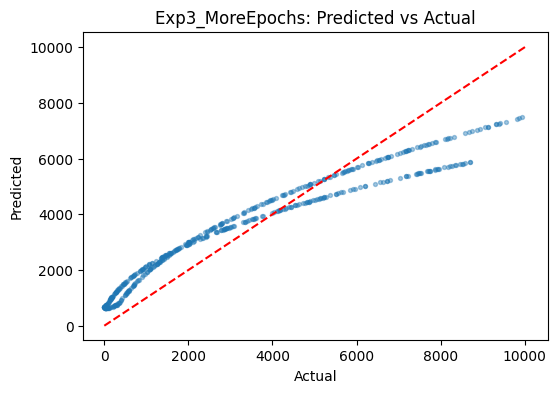

  [Exp4_TanhActivation] Epoch 100/500 | Train Loss: 0.97995 | Val Loss: 0.98150
  [Exp4_TanhActivation] Epoch 200/500 | Train Loss: 0.97659 | Val Loss: 0.97809
  [Exp4_TanhActivation] Epoch 300/500 | Train Loss: 0.97276 | Val Loss: 0.97420
  [Exp4_TanhActivation] Epoch 400/500 | Train Loss: 0.96813 | Val Loss: 0.96952
  [Exp4_TanhActivation] Epoch 500/500 | Train Loss: 0.96227 | Val Loss: 0.96359


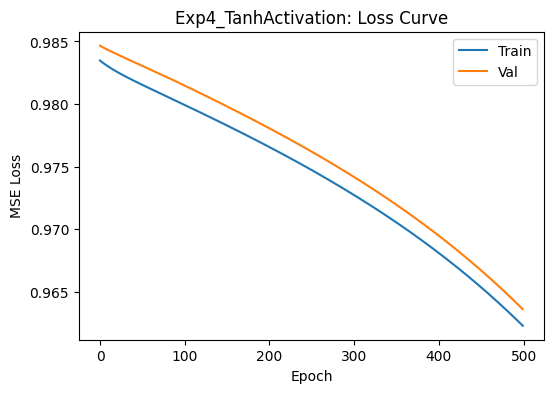

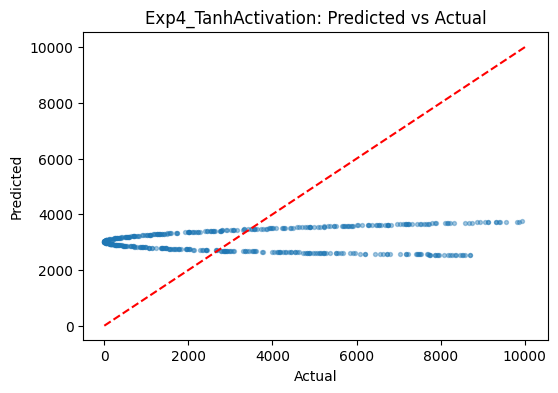

,Experiment,Learning Rate,Batch Size,Number of Epochs,Optimizer,Activation Function,Training R2 (Accuracy proxy),Validation R2 (Accuracy proxy),Test R2 (Accuracy proxy),Training Loss,Validation Loss,Test Loss
0,Baseline,0.003,Full (72000),500,Vanilla GD,relu,0.7121,0.7125,0.7132,0.287670,0.289666,0.288664
1,Exp1_HigherLR,0.015,Full (72000),500,Vanilla GD,relu,0.9870,0.9873,0.9870,0.012943,0.012769,0.013051
2,Exp2_LargerBatch,0.003,4096,500,Vanilla GD,relu,0.9990,0.9990,0.9989,0.001045,0.001014,0.001059
3,Exp3_MoreEpochs,0.003,Full (72000),700,Vanilla GD,relu,0.8664,0.8663,0.8664,0.133506,0.134715,0.134425
4,Exp4_TanhActivation,0.003,Full (72000),500,Vanilla GD,tanh,0.0369,0.0436,0.0377,0.962275,0.963595,0.968558


In [ ]:
# ============================================================
# PART B: HYPERPARAMETER EXPLORATION (4 experiments + baseline)
# Reuses your existing relu, mse_loss, xavier_initialization functions.
# ============================================================

import pandas as pd
from sklearn.model_selection import train_test_split

# --- Validation split out of the training data ---
X_tr, X_val, Y_tr, Y_val = train_test_split(
    X_train_scaled, Y_train_scaled, test_size=0.1, random_state=42
)

def tanh_act(z):
    return np.tanh(z)

def tanh_derivative(z):
    return 1 - np.tanh(z)**2

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

def forward_pass_generic(X, W1, b1, W2, b2, W3, b3, act='relu'):
    act_fn = relu if act == 'relu' else tanh_act
    z1 = X @ W1 + b1
    a1 = act_fn(z1)
    z2 = a1 @ W2 + b2
    a2 = act_fn(z2)
    z3 = a2 @ W3 + b3
    return z1, a1, z2, a2, z3

def backward_pass_generic(X, Y_true, z1, a1, z2, a2, Y_pred, W2, W3, act='relu'):
    deriv_fn = relu_derivative if act == 'relu' else tanh_derivative
    m = X.shape[0]
    dZ3 = (Y_pred - Y_true) * (2 / m)
    dW3 = a2.T @ dZ3
    db3 = np.sum(dZ3, axis=0, keepdims=True)

    dA2 = dZ3 @ W3.T
    dZ2 = dA2 * deriv_fn(z2)
    dW2 = a1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * deriv_fn(z1)
    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2, dW3, db3

def train_experiment(name, lr, epochs, batch_size, activation, patience=15):
    W1, b1, W2, b2, W3, b3 = xavier_initialization(1, hidden1, hidden2, 1)
    n = X_tr.shape[0]
    best_val_loss = float('inf')
    best_weights = None
    patience_counter = 0
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        perm = np.random.permutation(n)
        Xs, Ys = X_tr[perm], Y_tr[perm]
        bs = batch_size if batch_size else n  # full batch if None

        for start in range(0, n, bs):
            xb = Xs[start:start+bs]
            yb = Ys[start:start+bs]
            z1, a1, z2, a2, y_pred = forward_pass_generic(xb, W1, b1, W2, b2, W3, b3, activation)
            dW1, db1, dW2, db2, dW3, db3 = backward_pass_generic(xb, yb, z1, a1, z2, a2, y_pred, W2, W3, activation)
            W1 -= lr*dW1; b1 -= lr*db1
            W2 -= lr*dW2; b2 -= lr*db2
            W3 -= lr*dW3; b3 -= lr*db3

        _, _, _, _, tr_pred = forward_pass_generic(X_tr, W1, b1, W2, b2, W3, b3, activation)
        train_loss = mse_loss(Y_tr, tr_pred)
        _, _, _, _, val_pred = forward_pass_generic(X_val, W1, b1, W2, b2, W3, b3, activation)
        val_loss = mse_loss(Y_val, val_pred)
        train_losses.append(train_loss); val_losses.append(val_loss)
        if (epoch + 1) % 100 == 0:
            print(f"  [{name}] Epoch {epoch+1}/{epochs} | Train Loss: {train_loss:.5f} | Val Loss: {val_loss:.5f}")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = (W1.copy(), b1.copy(), W2.copy(), b2.copy(), W3.copy(), b3.copy())
            patience_counter = 0
        else:
            patience_counter += 1
        if patience_counter >= patience:
            break

    W1, b1, W2, b2, W3, b3 = best_weights
    _, _, _, _, test_pred = forward_pass_generic(X_test_scaled, W1, b1, W2, b2, W3, b3, activation)
    test_loss = mse_loss(Y_test_scaled, test_pred)

    row = {
        "Experiment": name,
        "Learning Rate": lr,
        "Batch Size": batch_size if batch_size else "Full (72000)",
        "Number of Epochs": len(train_losses),
        "Optimizer": "Vanilla GD",
        "Activation Function": activation,
        "Training R2 (Accuracy proxy)": round(r2(Y_tr, tr_pred), 4),
        "Validation R2 (Accuracy proxy)": round(r2(Y_val, val_pred), 4),
        "Test R2 (Accuracy proxy)": round(r2(Y_test_scaled, test_pred), 4),
        "Training Loss": round(train_losses[-1], 6),
        "Validation Loss": round(val_losses[-1], 6),
        "Test Loss": round(test_loss, 6),
    }

    # Plots
    plt.figure(figsize=(6,4))
    plt.plot(train_losses, label="Train")
    plt.plot(val_losses, label="Val")
    plt.title(f"{name}: Loss Curve")
    plt.xlabel("Epoch"); plt.ylabel("MSE Loss"); plt.legend()
    plt.savefig(f"{name.replace(' ','_')}_loss_curve.png", dpi=120, bbox_inches='tight')
    plt.show()

    y_pred_orig = scaler_Y.inverse_transform(test_pred)
    y_true_orig = scaler_Y.inverse_transform(Y_test_scaled)
    plt.figure(figsize=(6,4))
    plt.scatter(y_true_orig[:500], y_pred_orig[:500], alpha=0.4, s=8)
    plt.plot([y_true_orig.min(), y_true_orig.max()], [y_true_orig.min(), y_true_orig.max()], 'r--')
    plt.title(f"{name}: Predicted vs Actual")
    plt.xlabel("Actual"); plt.ylabel("Predicted")
    plt.savefig(f"{name.replace(' ','_')}_pred_vs_actual.png", dpi=120, bbox_inches='tight')
    plt.show()

    return row

# --- Run baseline + 4 experiments (one hyperparameter changed each time, kept fast) ---
np.random.seed(42)
results = []
results.append(train_experiment("Baseline",           lr=learning_rate,    epochs=500,  batch_size=None,  activation='relu'))
results.append(train_experiment("Exp1_HigherLR",      lr=learning_rate*5,  epochs=500,  batch_size=None,  activation='relu'))   # LR up
results.append(train_experiment("Exp2_LargerBatch",   lr=learning_rate,    epochs=500,  batch_size=4096,  activation='relu'))   # mini-batch, but large -> fast
results.append(train_experiment("Exp3_MoreEpochs",    lr=learning_rate,    epochs=700, batch_size=None,  activation='relu'))   # double epochs
results.append(train_experiment("Exp4_TanhActivation",lr=learning_rate,    epochs=500,  batch_size=None,  activation='tanh'))   # different activation

results_df = pd.DataFrame(results)
results_df.to_csv("hyperparameter_results.csv", index=False)
results_df